# Plot R-A curve

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        for line in file:
            parts = line.split()
            row = []
            for i, value in enumerate(parts):
                if i in [2, 3, 4]:  # 第三、四列可能不是 float
                    try:
                        row.append(float(value))
                    except ValueError:
                        row.append(None)  # 如果不是 float，使用 None 占位
                else:
                    row.append(float(value))
            data.append(row)
    return data


def plot_txt_files(folder_path, lower_bpp=0, upper_bpp=24):
    x_values_lsit = []
    y_values_list = []
    filename_list = []
    # for filename in ["ours.txt", "google.txt", "autojpeg.txt", "OptS.txt"]:
    for filename in ["ours.txt", "google.txt", "autojpeg.txt"]:
    # for filename in ["ours.txt", "google.txt"]:
    # for filename in ["ours.txt"]:
        file_path = os.path.join(folder_path, filename)
        data = read_file(file_path)
        x_values = [row[0] for row in data if row[0] is not None]  # bpp
        y_values = [row[1] for row in data if row[1] is not None]  # acc
        
        filtered_data = [(x, y) for x, y in zip(x_values, y_values) if (x>=lower_bpp and x<=upper_bpp)]
        x_values, y_values = zip(*filtered_data) if filtered_data else ([], [])
        if x_values and y_values:
            x_values_lsit.append(x_values)
            y_values_list.append(y_values)
            filename_list.append(filename.removesuffix('.txt'))
            plt.plot(x_values, y_values, label=filename.removesuffix('.txt'), clip_on=True)
    return x_values_lsit, y_values_list, filename_list


def plot_JPEG_baseline(path='./save/imagenet/mobilenet_v2/HDQ.txt', lower_qf=1, upper_qf=100, lower_bpp=0, upper_bpp=24):
    data = read_file(path)
    # plot baseline for HDQ
    QF_ls = [int(row[0]) for row in data]
    HDQ_y = [row[1] for row in data]
    HDQ_x = [row[2] for row in data]
    
    sorted_lists = [(qf, y, x) for qf, y, x in sorted(zip(QF_ls, HDQ_y, HDQ_x)) if (lower_qf<=qf and qf<=upper_qf) and (lower_bpp<=x and x<=upper_bpp)]

    QF_ls, HDQ_y, HDQ_x = map(list, zip(*sorted_lists))
    
    plt.plot(HDQ_x, HDQ_y, label="JPEG", color='k', linestyle='dashed', clip_on=True)
    # for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
    #     if QF_ls[i] % 10 == 0:
    #         plt.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(5,-7), ha='center', fontsize=8)

    return HDQ_x, HDQ_y


def plot_acc_gain(x1, y1, x2, y2, label=''):
    baseline_interpolator = interp1d(x2, y2, kind='linear', fill_value='extrapolate')
    y2_interp = baseline_interpolator(x1)
    acc_gain = y1 - y2_interp
    plt.plot(x1, acc_gain, label=label, clip_on=True)


dataset="imagenet"
# dataset="CUB200"
# dataset="Flowers"
# dataset="Pets"
# dataset="STANFORD120"

# model="mobilenet_v2"
# model="Mnasnet"
model="Swin_T"
# model="ConvNeXt_tiny"
# model="resnet18"

base_path = './save/{}/{}'.format(dataset,model)
result_folder = "./save/Results"
plot_path = os.path.join(result_folder, "{}/{}".format(dataset,model))

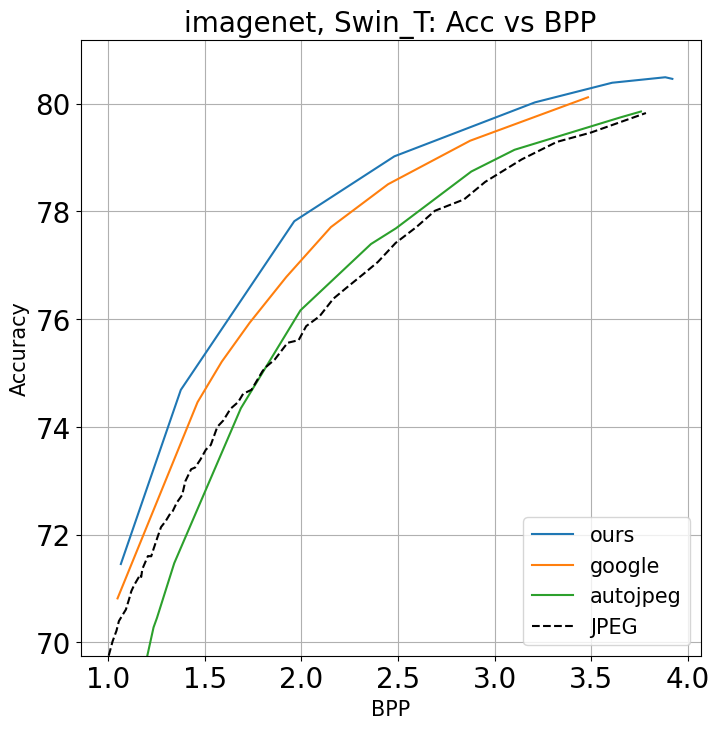

In [12]:
plt.figure(figsize=(8,8))
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

# lower_bpp=0.3
# upper_bpp=1

# lower_bpp=0.5
# upper_bpp=1.5

lower_bpp=1
upper_bpp=4

X_list, Y_list, fn_list = plot_txt_files(plot_path, lower_bpp=lower_bpp, upper_bpp=upper_bpp)
x2, y2 = plot_JPEG_baseline(path=os.path.join(plot_path, "JPEG_baseline.txt"), lower_bpp=lower_bpp, upper_bpp=upper_bpp)

plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
x_range = np.maximum(np.round((x_max - x_min) / 4, 1), 0.02)
y_range = np.maximum(np.round((y_max - y_min) / 4, 1), 0.02)
# plt.xticks(np.arange(np.round(x_min, 1), np.round(x_max, 1), x_range))
# plt.yticks(np.arange(np.round(y_min, 1), np.round(y_max, 1), y_range))
plt.ylim(min(y2), y_max)
plt.title("{}, {}: ".format(dataset, model) + 'Acc vs BPP') 
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

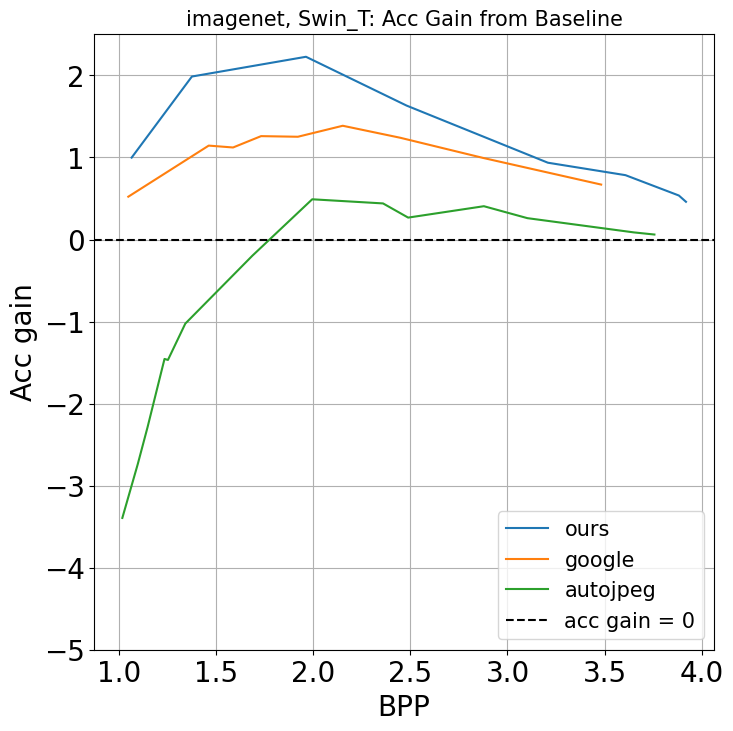

In [13]:
# plot acc gain
plt.figure(figsize=(8,8))
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

for idx, (x1, y1, fn) in enumerate(zip(X_list, Y_list, fn_list)):
    plot_acc_gain(x1, y1, x2, y2, fn)

plt.axhline(y=0, color='black', linestyle='--', label="acc gain = 0")
x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
# x_range = np.maximum(np.round((x_max-x_min)/15,1), 0.01)
# y_range = np.maximum(np.round((y_max-y_min)/15,1), 0.01)
# plt.xticks(np.arange(np.round(x_min,1), np.round(x_max,1), x_range))
# plt.yticks(np.arange(np.round(y_min,1), np.round(y_max,1), y_range))
plt.ylim(-5, y_max)
plt.title("{}, {}: ".format(dataset, model) + 'Acc Gain from Baseline', fontsize=15)
plt.xlabel('BPP')
plt.ylabel('Acc gain')
plt.legend(loc="lower right")
plt.grid()
plt.show()

# Plot Correlation

10000
P-value: 0.0
10000
P-value: 0.0
10000
P-value: 0.0


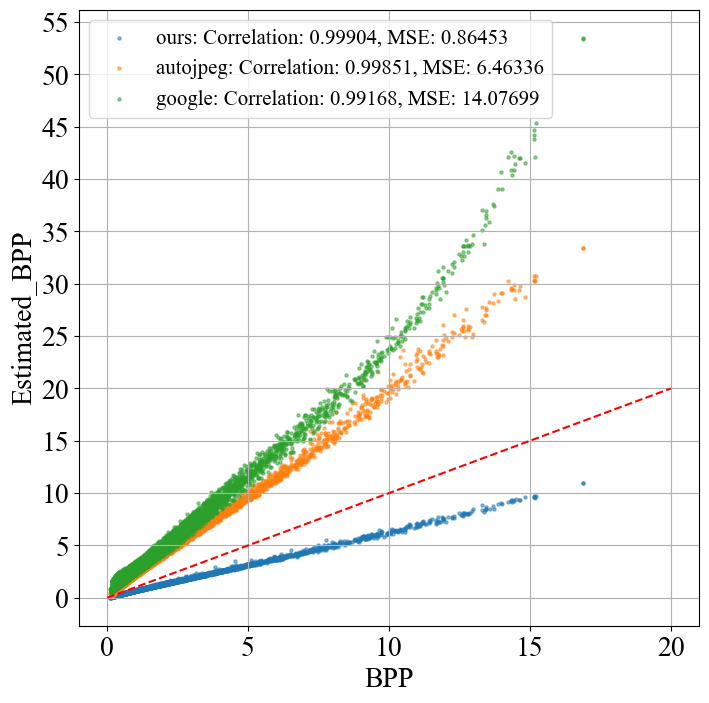

In [286]:
from scipy.stats import pearsonr
import numpy as np

def plot_correlation_ours(path):
    Y_data = read_file(path)
    print(len(Y_data))
    Entropy = [(row[1]+row[2]+row[3]+row[4]) for row in Y_data] # entropy
    bpp = [(row[0]) for row in Y_data] # test bpp

    mse = np.mean((np.array(Entropy) - np.array(bpp)) ** 2)
    correlation, p_value = pearsonr(Entropy, bpp)
    print(f"P-value: {p_value}")

    plt.scatter(bpp, Entropy, s=5, label="ours: Correlation: {:.5f}, MSE: {:.5f}".format(correlation, mse), alpha=0.5)
    return 

def plot_correlation_autojpeg(path):
    Y_data = read_file(path)
    print(len(Y_data))
    Entropy = [(row[1]) for row in Y_data] # entropy
    bpp = [(row[0]) for row in Y_data] # test bpp

    mse = np.mean((np.array(Entropy) - np.array(bpp)) ** 2)
    correlation, p_value = pearsonr(Entropy, bpp)
    print(f"P-value: {p_value}")

    plt.scatter(bpp, Entropy, s=5, label="autojpeg: Correlation: {:.5f}, MSE: {:.5f}".format(correlation, mse), alpha=0.5)
    return 

def plot_correlation_google(path):
    Y_data = read_file(path)
    print(len(Y_data))
    Entropy = [(row[1]+row[2]+row[3]+row[4]) for row in Y_data] # entropy
    bpp = [(row[0]) for row in Y_data] # test bpp

    mse = np.mean((np.array(Entropy) - np.array(bpp)) ** 2)
    correlation, p_value = pearsonr(Entropy, bpp)
    print(f"P-value: {p_value}")

    plt.scatter(bpp, Entropy, s=5, label="google: Correlation: {:.5f}, MSE: {:.5f}".format(correlation, mse), alpha=0.5)
    return 

plt.figure(figsize=(8, 8))
plot_correlation_ours("./save/Results/ours_BPP_Entropy_correlation_alpha_100.txt")
plot_correlation_autojpeg("./save/Results/autojpeg_BPP_Entropy_correlation.txt")
plot_correlation_google("./save/Results/google_BPP_Entropy_correlation.txt")
plt.plot([0, 20], [0, 20], color='red', linestyle='--')

plt.rcParams["font.family"] = "Times New Roman"
font = 20
# Set the default text font size
# plt.rc('font', size=14, weight='bold')
plt.rc('figure', figsize = (8,6))
# plt.rc('figure', autolayout = True)
plt.rc('font', size=font+4)
# Set the axes title font size
plt.rc('axes', titlesize=font)
# Set the axes labels font size
plt.rc('axes', labelsize=font)
# Set the font size for x tick labels
plt.rc('xtick', labelsize=font)
# Set the font size for y tick labels
plt.rc('ytick', labelsize=font)
# Set the legend font size
plt.rc('legend', fontsize=15)
# Set the font size of the figure title
plt.rc('figure', titlesize=font)

# plt.title(f'Entropy vs BPP')
plt.xlabel('BPP')
plt.ylabel('Estimated_BPP')
plt.grid(True)
plt.legend(loc="upper left")
# plt.xticks(np.arange(0, np.round(x_max), 5))
plt.yticks(np.arange(0, np.round(y_max), 5))
plt.show()